# BÀI THỰC HÀNH 2.3: TINH CHỈNH THAM SỐ CÂY QUYẾT ĐỊNH VỚI GRIDSEARCHCV ĐỂ TỐI ƯU F-SCORE
**Họ và tên:** Thái Anh Lạc  
**MSSV:** 089206000860  
**Mã lớp học phần:** 012012204103  
**Môn học:** Khai thác dữ liệu (Data Mining)


### 1. Khởi tạo, cấu hình PATH cho Graphviz và nạp các thư viện cần thiết


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

for g_path in [r"C:\Program Files\Graphviz\bin", r"C:\Program Files (x86)\Graphviz\bin"]:
    if os.path.exists(g_path) and g_path not in os.environ['PATH']:
        os.environ['PATH'] = g_path + os.pathsep + os.environ['PATH']

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, export_graphviz
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, classification_report
import graphviz

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print("Import các thư viện và cấu hình môi trường thành công!")


Import các thư viện và cấu hình môi trường thành công!


### 2. Nạp dữ liệu Iris, phân chia tập Train / Test (70% - 30%) và chuẩn hóa


In [2]:
iris = load_iris()
X, y = iris.data, iris.target
feature_names, target_names = iris.feature_names, iris.target_names

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Tổng số mẫu Iris:    {len(X)} mẫu")
print(f"Tập Train (70%):     {X_train_scaled.shape[0]} mẫu (Shape: {X_train_scaled.shape})")
print(f"Tập Test (30%):      {X_test_scaled.shape[0]} mẫu (Shape: {X_test_scaled.shape})")


Tổng số mẫu Iris:    150 mẫu
Tập Train (70%):     105 mẫu (Shape: (105, 4))
Tập Test (30%):      45 mẫu (Shape: (45, 4))


### 3. Đánh giá mô hình cơ sở mặc định (Baseline Model) trước khi tinh chỉnh


In [3]:
baseline_model = DecisionTreeClassifier(random_state=42)
baseline_model.fit(X_train_scaled, y_train)

base_train_acc = baseline_model.score(X_train_scaled, y_train)
y_pred_base = baseline_model.predict(X_test_scaled)

base_test_acc = accuracy_score(y_test, y_pred_base)
base_f1_weighted = f1_score(y_test, y_pred_base, average='weighted')
base_f1_macro = f1_score(y_test, y_pred_base, average='macro')

print("=== KẾT QUẢ MÔ HÌNH MẶC ĐỊNH (BASELINE TRƯỚC KHI TINH CHỈNH) ===")
print(f"Độ sâu của cây mặc định:              {baseline_model.get_depth()} tầng")
print(f"Tổng số nút lá:                       {baseline_model.get_n_leaves()} lá")
print(f"1. Độ chính xác tập TRAIN:           {base_train_acc * 100:.2f}% ({base_train_acc:.4f})  <-- Học thuộc lòng 100%")
print(f"2. Độ chính xác tập TEST (Accuracy): {base_test_acc * 100:.2f}% ({base_test_acc:.4f})")
print(f"3. Độ chênh lệch Train - Test:       {(base_train_acc - base_test_acc) * 100:.2f}%       <-- Dấu hiệu Overfitting")
print(f"4. F1-Score Test (Weighted):         {base_f1_weighted * 100:.2f}% ({base_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {base_f1_macro * 100:.2f}% ({base_f1_macro:.4f})")


=== KẾT QUẢ MÔ HÌNH MẶC ĐỊNH (BASELINE TRƯỚC KHI TINH CHỈNH) ===
Độ sâu của cây mặc định:              5 tầng
Tổng số nút lá:                       8 lá
1. Độ chính xác tập TRAIN:           100.00% (1.0000)  <-- Học thuộc lòng 100%
2. Độ chính xác tập TEST (Accuracy): 91.11% (0.9111)
3. Độ chênh lệch Train - Test:       8.89%       <-- Dấu hiệu Overfitting
4. F1-Score Test (Weighted):         91.07% (0.9107)
5. F1-Score Test (Macro):            91.07% (0.9107)


### 4. Thiết lập và thực thi tinh chỉnh tham số với GridSearchCV (Mục tiêu: Tối ưu F-Score)


In [4]:
param_grid = {
    'criterion': ['gini', 'entropy', 'log_loss'],
    'max_depth': [2, 3, 4, 5, 6, None],
    'min_samples_split': [2, 3, 5, 10],
    'min_samples_leaf': [1, 2, 3, 4, 5]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1_weighted',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_scaled, y_train)

print("\n=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV ===")
print("Bộ tham số tối ưu nhất cho F-Score cao nhất:")
for param, val in grid_search.best_params_.items():
    print(f"   - {param:<20}: {val}")

print(f"\nĐiểm F1-Score trung bình cao nhất qua 5-Fold CV: {grid_search.best_score_ * 100:.2f}% ({grid_search.best_score_:.4f})")


Fitting 5 folds for each of 360 candidates, totalling 1800 fits



=== KẾT QUẢ TINH CHỈNH THAM SỐ VỚI GRIDSEARCHCV ===
Bộ tham số tối ưu nhất cho F-Score cao nhất:
   - criterion           : gini
   - max_depth           : 3
   - min_samples_leaf    : 1
   - min_samples_split   : 2

Điểm F1-Score trung bình cao nhất qua 5-Fold CV: 95.22% (0.9522)


### 5. Phân tích Top 5 bộ tham số tốt nhất từ kết quả GridSearchCV


In [5]:
results_df = pd.DataFrame(grid_search.cv_results_)
columns_to_show = [
    'param_criterion', 'param_max_depth', 'param_min_samples_split', 
    'param_min_samples_leaf', 'mean_test_score', 'std_test_score', 'rank_test_score'
]
top_5_params = results_df[columns_to_show].sort_values(by='rank_test_score').head(5)

print("=== TOP 5 BỘ THAM SỐ ĐẠT F1-SCORE CAO NHẤT QUA CROSS-VALIDATION ===")
print(top_5_params.to_string(index=False))


=== TOP 5 BỘ THAM SỐ ĐẠT F1-SCORE CAO NHẤT QUA CROSS-VALIDATION ===
param_criterion param_max_depth  param_min_samples_split  param_min_samples_leaf  mean_test_score  std_test_score  rank_test_score
           gini               3                        3                       1         0.952234        0.030117                1
           gini               3                        2                       1         0.952234        0.030117                1
           gini               3                       10                       1         0.952234        0.030117                1
           gini               3                        5                       1         0.952234        0.030117                1
           gini               3                        2                       2         0.952234        0.030117                1


### 6. Kiểm thử và đánh giá mô hình tối ưu trên tập Test độc lập


=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===
1. Độ chính xác tập TRAIN:           98.10% (0.9810)
2. Độ chính xác tập TEST (Accuracy): 97.78% (0.9778)  <-- Bật tăng mạnh!
3. Độ chênh lệch Train - Test:       0.32%       <-- Triệt tiêu Overfitting!
4. F1-Score Test (Weighted):         97.78% (0.9778)
5. F1-Score Test (Macro):            97.78% (0.9778)

=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===
              precision    recall  f1-score   support

      setosa     1.0000    1.0000    1.0000        15
  versicolor     0.9375    1.0000    0.9677        15
   virginica     1.0000    0.9333    0.9655        15

    accuracy                         0.9778        45
   macro avg     0.9792    0.9778    0.9778        45
weighted avg     0.9792    0.9778    0.9778        45



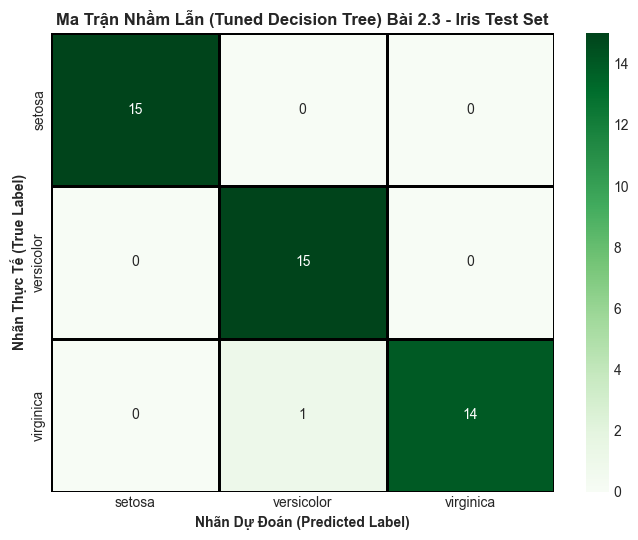

In [6]:
best_model = grid_search.best_estimator_

best_train_acc = best_model.score(X_train_scaled, y_train)
y_pred_best = best_model.predict(X_test_scaled)

best_test_acc = accuracy_score(y_test, y_pred_best)
best_f1_weighted = f1_score(y_test, y_pred_best, average='weighted')
best_f1_macro = f1_score(y_test, y_pred_best, average='macro')
cm_best = confusion_matrix(y_test, y_pred_best)

print("=== KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH ĐÃ TINH CHỈNH TỐI ƯU TRÊN TẬP TEST ===")
print(f"1. Độ chính xác tập TRAIN:           {best_train_acc * 100:.2f}% ({best_train_acc:.4f})")
print(f"2. Độ chính xác tập TEST (Accuracy): {best_test_acc * 100:.2f}% ({best_test_acc:.4f})  <-- Bật tăng mạnh!")
print(f"3. Độ chênh lệch Train - Test:       {(best_train_acc - best_test_acc) * 100:.2f}%       <-- Triệt tiêu Overfitting!")
print(f"4. F1-Score Test (Weighted):         {best_f1_weighted * 100:.2f}% ({best_f1_weighted:.4f})")
print(f"5. F1-Score Test (Macro):            {best_f1_macro * 100:.2f}% ({best_f1_macro:.4f})")

print("\n=== BÁO CÁO PHÂN LOẠI CHI TIẾT (CLASSIFICATION REPORT) ===")
print(classification_report(y_test, y_pred_best, target_names=target_names, digits=4))

plt.figure(figsize=(7, 5.5))
sns.heatmap(cm_best, annot=True, fmt='d', cmap='Greens', xticklabels=target_names, yticklabels=target_names, cbar=True, linewidths=1, linecolor='black')
plt.title("Ma Trận Nhầm Lẫn (Tuned Decision Tree) Bài 2.3 - Iris Test Set", fontweight='bold', fontsize=12)
plt.xlabel("Nhãn Dự Đoán (Predicted Label)", fontweight='bold')
plt.ylabel("Nhãn Thực Tế (True Label)", fontweight='bold')
plt.tight_layout()
plt.show()


### 7. Bảng đối sánh hiệu năng trước và sau khi tinh chỉnh tham số


In [7]:
comparison_data = {
    "Tiêu chí": [
        "Tiêu chuẩn phân chia (criterion)",
        "Độ sâu của cây (max_depth)",
        "Số mẫu tối thiểu chia nút (min_samples_split)",
        "Số mẫu tối thiểu nút lá (min_samples_leaf)",
        "Tổng số nút lá (leaves count)",
        "Độ chính xác tập Train (Train Acc)",
        "Độ chính xác tập Test (Test Acc)",
        "Độ chênh lệch Train - Test (Gap)",
        "F1-Score Test (Weighted)",
        "F1-Score Test (Macro)"
    ],
    "Mô hình Mặc định (Baseline)": [
        baseline_model.criterion,
        str(baseline_model.get_depth()),
        str(baseline_model.min_samples_split),
        str(baseline_model.min_samples_leaf),
        str(baseline_model.get_n_leaves()),
        f"{base_train_acc * 100:.2f}%",
        f"{base_test_acc * 100:.2f}%",
        f"{(base_train_acc - base_test_acc) * 100:.2f}% (Overfitting)",
        f"{base_f1_weighted * 100:.2f}%",
        f"{base_f1_macro * 100:.2f}%"
    ],
    "Mô hình Tối ưu (GridSearchCV)": [
        best_model.criterion,
        str(best_model.get_depth()),
        str(best_model.min_samples_split),
        str(best_model.min_samples_leaf),
        str(best_model.get_n_leaves()),
        f"{best_train_acc * 100:.2f}%",
        f"{best_test_acc * 100:.2f}%",
        f"{(best_train_acc - best_test_acc) * 100:.2f}% (Tối ưu)",
        f"{best_f1_weighted * 100:.2f}%",
        f"{best_f1_macro * 100:.2f}%"
    ]
}

df_compare = pd.DataFrame(comparison_data)
print("=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (BÀI 2.3) ===")
print(df_compare.to_string(index=False))


=== BẢNG SO SÁNH HIỆU NĂNG TRƯỚC VÀ SAU KHI TINH CHỈNH (BÀI 2.3) ===
                                     Tiêu chí Mô hình Mặc định (Baseline) Mô hình Tối ưu (GridSearchCV)
             Tiêu chuẩn phân chia (criterion)                        gini                          gini
                   Độ sâu của cây (max_depth)                           5                             3
Số mẫu tối thiểu chia nút (min_samples_split)                           2                             2
   Số mẫu tối thiểu nút lá (min_samples_leaf)                           1                             1
                Tổng số nút lá (leaves count)                           8                             5
           Độ chính xác tập Train (Train Acc)                     100.00%                        98.10%
             Độ chính xác tập Test (Test Acc)                      91.11%                        97.78%
             Độ chênh lệch Train - Test (Gap)         8.89% (Overfitting)                0.32% (Tối

### 8. Trực quan hóa cây quyết định đã được tinh chỉnh tối ưu


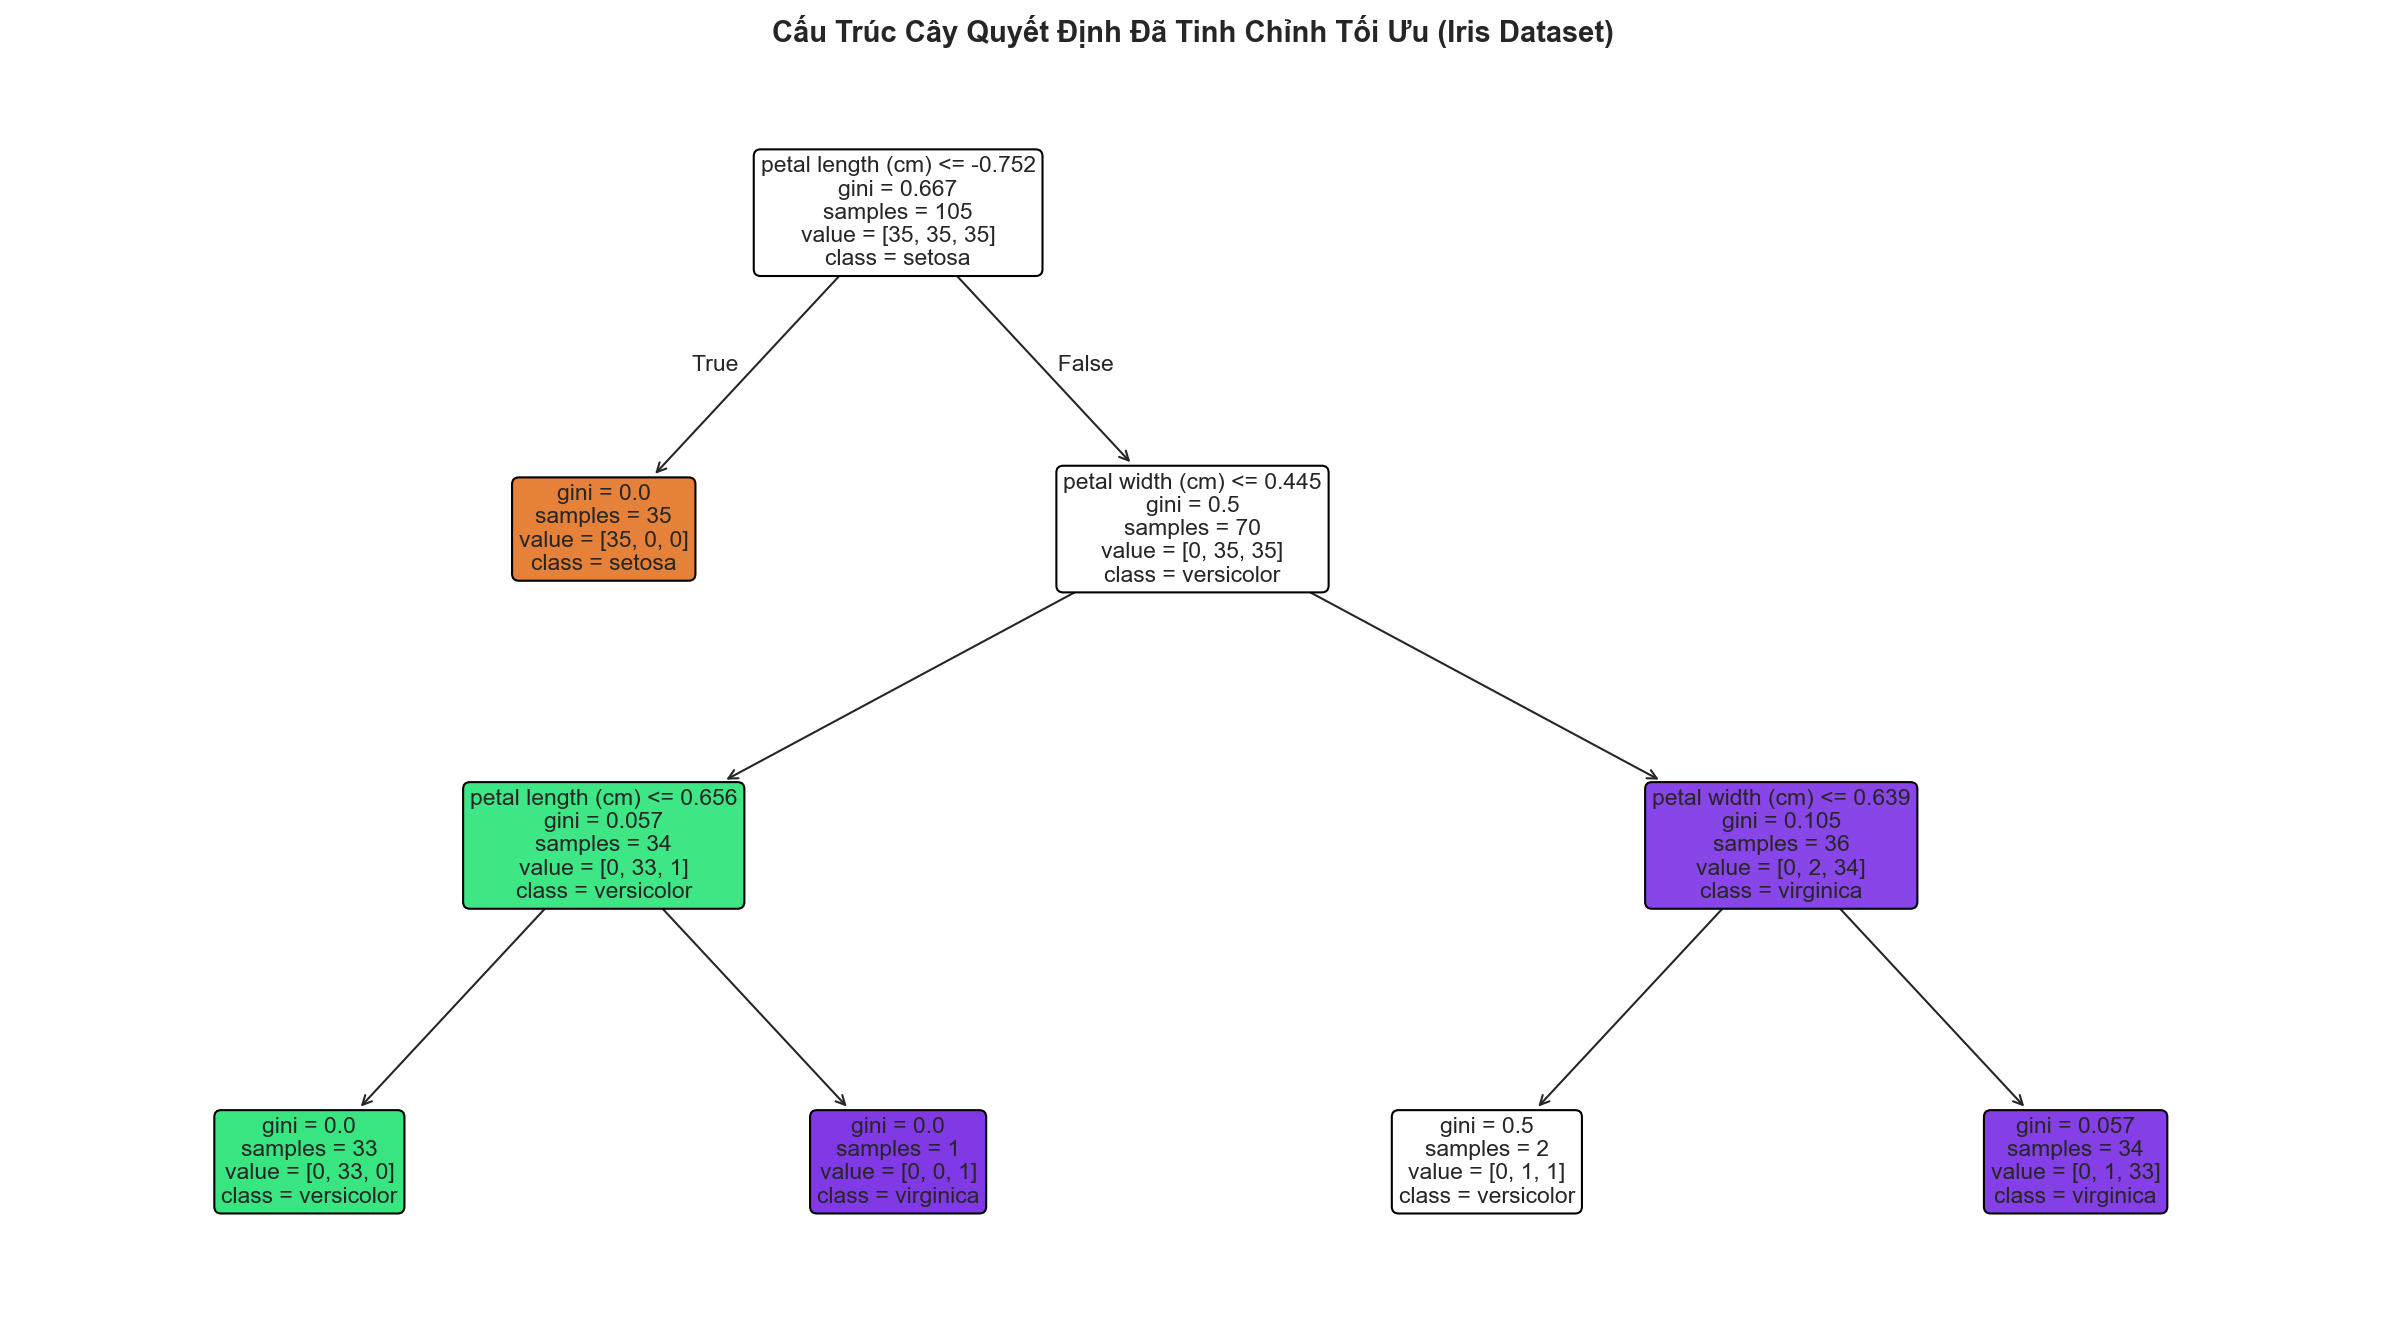

Đã xuất ảnh Graphviz 'iris_tuned_decision_tree.png'!

=== TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU (TEXT RULES) ===
|--- petal length (cm) <= -0.75
|   |--- class: 0
|--- petal length (cm) >  -0.75
|   |--- petal width (cm) <= 0.44
|   |   |--- petal length (cm) <= 0.66
|   |   |   |--- class: 1
|   |   |--- petal length (cm) >  0.66
|   |   |   |--- class: 2
|   |--- petal width (cm) >  0.44
|   |   |--- petal width (cm) <= 0.64
|   |   |   |--- class: 1
|   |   |--- petal width (cm) >  0.64
|   |   |   |--- class: 2



In [8]:
plt.figure(figsize=(16, 9), dpi=150)
plot_tree(best_model, feature_names=feature_names, class_names=target_names, filled=True, rounded=True, fontsize=11)
plt.title("Cấu Trúc Cây Quyết Định Đã Tinh Chỉnh Tối Ưu (Iris Dataset)", fontweight='bold', fontsize=14)
plt.tight_layout()
plt.show()

dot_data_best = export_graphviz(best_model, out_file=None, feature_names=feature_names, class_names=target_names, filled=True, rounded=True)
try:
    graphviz.Source(dot_data_best).render("iris_tuned_decision_tree", format="png", cleanup=True)
    print("Đã xuất ảnh Graphviz 'iris_tuned_decision_tree.png'!")
except Exception as e:
    print("Graphviz render notice:", e)

print("\n=== TẬP LUẬT QUYẾT ĐỊNH TỐI ƯU (TEXT RULES) ===")
print(export_text(best_model, feature_names=list(feature_names)))
